# Contralesional Motor-Intent Decoding after Stroke
## Notebook 04 · Advanced EEG analyses

*Case study: EEG pipeline for an IpsiHand-type contralesional BCI · November 2026*

### Executive summary
| Analysis | Main result | Relevance for Kandu |
|---|---|---|
| ICA vs EOG regression | 1 ocular component found automatically; at C3 the two methods agree (r = 0.88 in 8–30 Hz) | regression is an adequate, online-capable substitute for ICA on a 6-electrode headset |
| Spectral parameterisation | 1/f exponent, μ/α and β peaks do **not** differ between hemispheres (all p > 0.4) | interhemispheric differences are in the *task response*, not the resting spectrum |
| Stroke markers (pdBSI, DAR) | no correlation with NIHSS / MBI / mRS after correction (strongest: lesioned-side DAR vs mRS, ρ = 0.38, uncorrected p = 0.009) | task recordings are a poor substitute for a resting recording |
| Connectivity (wPLI) | no significant task-related change; C3–C4 coupling unchanged | connectivity is not a better control feature than local power |
| Cluster permutation (time × frequency) | significant ERD 10–25 Hz on both hemispheres; larger on the healthy side (57% vs 42% of the map) | rigorous group-level confirmation of the healthy-side ERD |
| MRCP grand averages | dominated by a cue-evoked positivity at 0.3–0.6 s and a pre-cue negativity | cue-locked "MRCP" decoding is partly sensory; use self-paced validation |
| Reliability of ERD | split-half reliability 0.26 with ~20 trials | single-session ERD is too noisy to track recovery; ~10× more trials needed for 0.8 |
| Learning curves | stroke: plateau ~10 trials/class (AUC 0.77); SCI attempt: 0.87 at 20, 0.92 at 60 attempts/class | ~40–60 attempts per class give > 0.9 with attempted movement |
| Cross-subject transfer | calibration-free AUC 0.70 (stroke), 0.84 (SCI), 0.85 (healthy) = 89–93% of calibrated | a pooled model can start a session; re-centring matters in stroke |
| EEGNet | below Riemann cross-subject in stroke (0.62 vs 0.70, p = 0.001); n.s. within-subject in SCI (0.92 vs 0.95) | with these data sizes, Riemannian geometry remains the better choice |

### Contents
1 ICA artefact decomposition · 2 Spectral parameterisation (aperiodic + peaks) · 3 Stroke EEG markers (BSI, DAR) · 4 Functional connectivity (wPLI) · 5 Group time-frequency statistics (cluster permutation) · 6 Movement-related cortical potentials · 7 Reliability of the ERD · 8 Calibration length (learning curves) · 9 Cross-subject transfer (calibration-free decoding) · 10 Deep learning (EEGNet) · 11 Summary

Sections 1–2 run live on patient 02. Group results come from `scripts/run_advanced.py` (`results/adv_*`).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
from scipy import stats, signal
from kandu_eeg import config as C, io, preprocessing as P, spatial as S, advanced as A, viz as V
mne.set_log_level("ERROR"); V.set_style(); R = C.RESULTS_DIR
part = io.load_participants()
markers = pd.read_csv(R / "adv_liu_markers.csv").set_index("subject").join(part[["NIHSS", "MBI", "mRS", "Duration", "Age", "cortical_lesion"]])
def holm(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o])); return adj
print(f"{len(markers)} patients")

47 patients


## 1 · Independent component analysis (ICA) for artefacts
**ICA** assumes the recording is a linear mix of statistically independent sources (brain rhythms, eye blinks, muscle, heartbeat). It finds an "unmixing" matrix that recovers those sources as **components**. Each component has a time course and a scalp map. Artefact components are identified and removed, and the data are rebuilt from the rest.

- Fitted on 1–40 Hz data (ICA is unstable with slow drifts), here with FastICA and 20 components.
- Eye components are found **automatically** by correlating each component's time course with the EOG channels (`find_bads_eog`).
- **Why the main pipeline uses regression instead:** ICA needs many channels (≥ ~20) to separate sources and is fitted offline. A 6-electrode headset cannot run it, while EOG regression works with any number of channels and in real time. Below we check how close the two methods get, both broadband and in the 8–30 Hz band the decoder uses.

EOG components: [1]


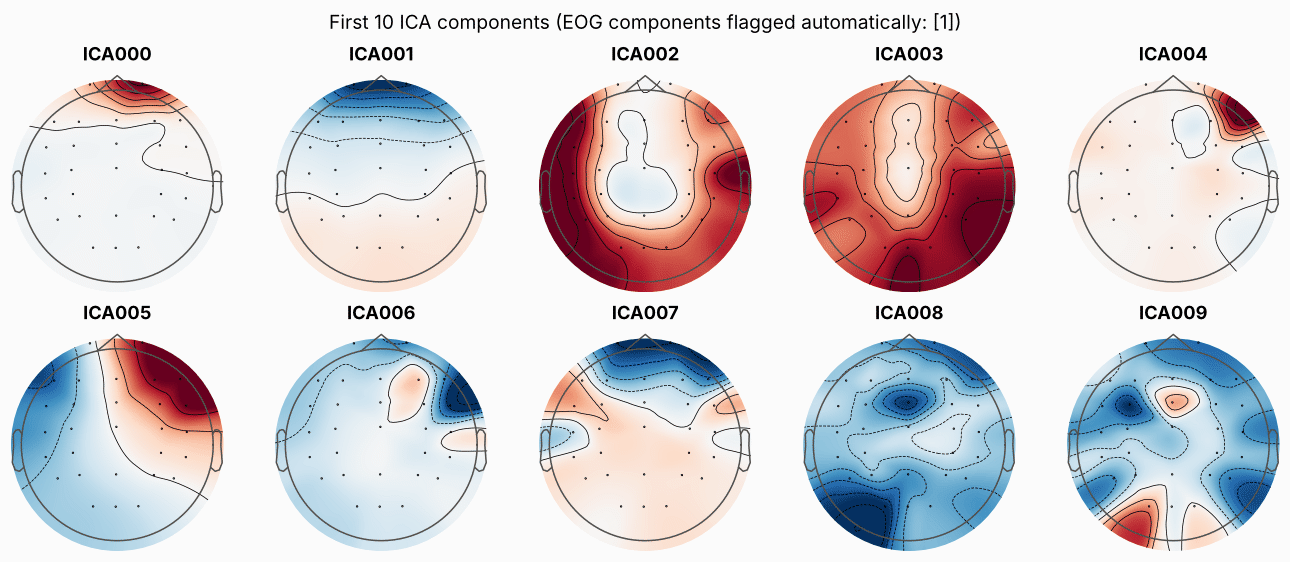

In [2]:
SUBJECT = 2
raw = P.downsample(P.filter_offline(P.remove_dc(io.load_raw(SUBJECT))))
ica = mne.preprocessing.ICA(n_components=20, method="fastica", random_state=0, max_iter=1000)
ica.fit(raw, picks="eeg")
eog_idx, scores = ica.find_bads_eog(raw, ch_name=["HEOL", "VEOR"], threshold=3.0)
eog_idx = [int(i) for i in eog_idx]
print("EOG components:", eog_idx)
fig = ica.plot_components(picks=range(10), show=False); fig.set_size_inches(12, 5); fig.suptitle("First 10 ICA components (EOG components flagged automatically: " + str(eog_idx) + ")"); plt.show()

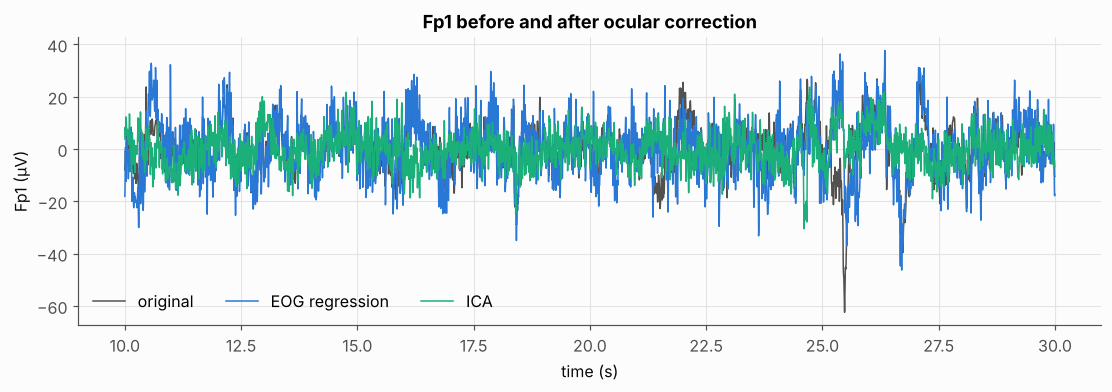

C3 after regression vs after ICA: broadband r = 0.788; in the 8-30 Hz decoding band r = 0.882


In [3]:
clean_ica = ica.apply(raw.copy(), exclude=eog_idx)
clean_reg, _ = P.eog_regression(raw)
seg = slice(int(10 * 250), int(30 * 250))
fp1 = [raw.get_data(picks="Fp1")[0][seg], clean_reg.get_data(picks="Fp1")[0][seg], clean_ica.get_data(picks="Fp1")[0][seg]]
c3 = [r.get_data(picks="C3")[0] for r in (clean_reg, clean_ica)]
fig, ax = plt.subplots(figsize=(12, 3.4)); t = np.arange(seg.stop - seg.start) / 250 + 10
for x, lab, col in zip(fp1, ["original", "EOG regression", "ICA"], [V.INK2, V.SERIES[0], V.SERIES[2]]):
    ax.plot(t, x * 1e6, lw=1, label=lab, color=col)
ax.set_xlabel("time (s)"); ax.set_ylabel("Fp1 (µV)"); ax.legend(ncol=3); ax.set_title("Fp1 before and after ocular correction"); plt.show()
sos = signal.butter(4, [8, 30], "bandpass", fs=250, output="sos")
c3b = [signal.sosfiltfilt(sos, x) for x in c3]
print(f"C3 after regression vs after ICA: broadband r = {np.corrcoef(*c3)[0, 1]:.3f}; in the 8-30 Hz decoding band r = {np.corrcoef(*c3b)[0, 1]:.3f}")

## 2 · Spectral parameterisation: separating rhythms from the 1/f background
A power spectrum is two things added together: an **aperiodic** 1/f background and **periodic** peaks (μ, β). Classic band power mixes them: a change in "beta power" can be a change in the rhythm *or* a tilt of the background. **FOOOF / specparam** (Donoghue et al., *Nat Neurosci* 2020) fits:

log10 P(f) = offset − log10(f^exponent) + Σ Gaussian peaks

- **Exponent** (steepness of the 1/f): linked to the excitation / inhibition balance. Steeper = more inhibition / slower activity.
- **Peak centre frequency** of μ/α: slows after brain injury.

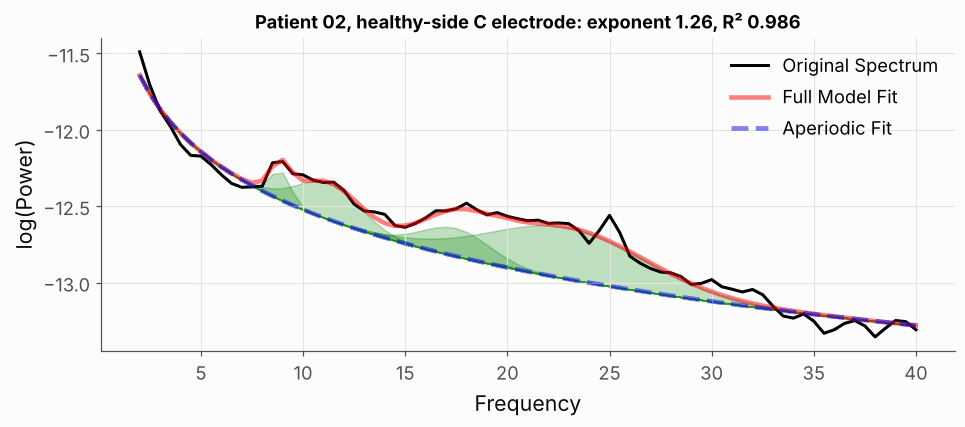

peaks (centre Hz, power above 1/f, bandwidth Hz):
[[ 8.87  0.27  1.  ]
 [11.26  0.24  3.09]
 [17.45  0.31  3.35]
 [19.93  0.32  1.  ]
 [21.3   0.33  1.  ]
 [22.94  0.34  7.71]]


In [4]:
ex = np.load(R / "adv_example_spectrum.npz")
from fooof import FOOOF
fm = FOOOF(peak_width_limits=(1, 8), max_n_peaks=6, min_peak_height=0.05, verbose=False); fm.fit(ex["f"], ex["psd"], [2, 40])
fig, ax = plt.subplots(figsize=(9, 4)); fm.plot(ax=ax, plot_peaks="shade", add_legend=True); ax.set_title(f"Patient {SUBJECT:02d}, healthy-side C electrode: exponent {fm.aperiodic_params_[1]:.2f}, R² {fm.r_squared_:.3f}"); plt.show()
print("peaks (centre Hz, power above 1/f, bandwidth Hz):"); print(np.round(fm.peak_params_, 2))

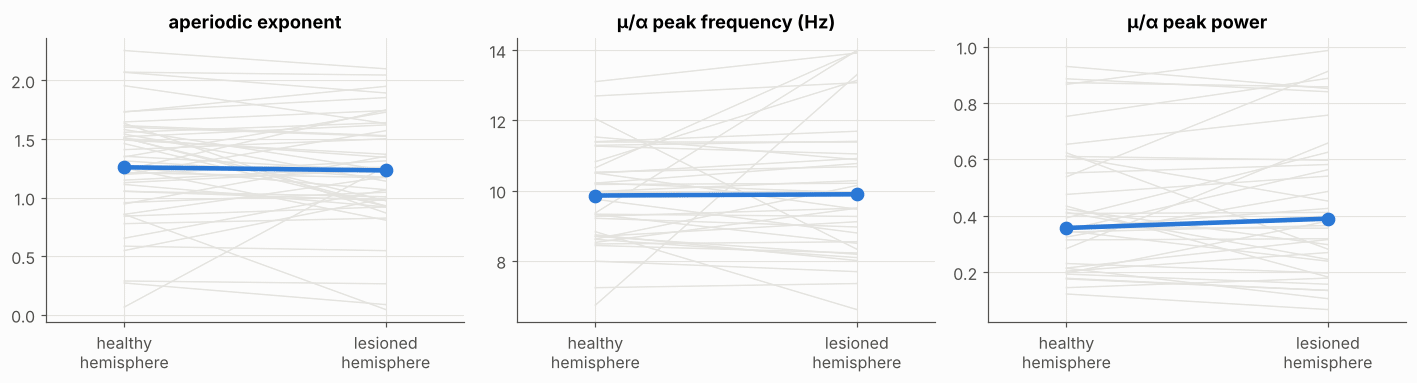

fit quality: median R² = 0.986


,measure,healthy_side_median,lesioned_side_median,n,p,p_holm
0,aperiodic exponent,1.2587,1.2319,47,0.4592,1.0
1,aperiodic offset,-11.1131,-11.2237,47,0.6787,1.0
2,μ/α peak frequency (Hz),9.8598,9.8958,36,0.6581,1.0
3,μ/α peak power,0.3567,0.3898,36,0.5189,1.0
4,β peak frequency (Hz),22.3737,21.8348,36,0.7386,1.0


In [5]:
rows = []
for meas, lab in [("exponent", "aperiodic exponent"), ("offset", "aperiodic offset"), ("alpha_cf", "μ/α peak frequency (Hz)"), ("alpha_pw", "μ/α peak power"), ("beta_cf", "β peak frequency (Hz)")]:
    a, b = markers[f"{meas}_CL"], markers[f"{meas}_IL"]; m = a.notna() & b.notna()
    rows.append(dict(measure=lab, healthy_side_median=a[m].median(), lesioned_side_median=b[m].median(), n=int(m.sum()), p=stats.wilcoxon(a[m], b[m]).pvalue))
t = pd.DataFrame(rows); t["p_holm"] = holm(t.p)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a_, meas, lab in zip(ax, ["exponent", "alpha_cf", "alpha_pw"], ["aperiodic exponent", "μ/α peak frequency (Hz)", "μ/α peak power"]):
    d = markers[[f"{meas}_CL", f"{meas}_IL"]].dropna()
    a_.plot([0, 1], d.T.values, color=V.GRID, lw=1); a_.plot([0, 1], d.median().values, color=V.SERIES[0], lw=3, marker="o", ms=8)
    a_.set_xticks([0, 1]); a_.set_xticklabels(["healthy\nhemisphere", "lesioned\nhemisphere"]); a_.set_xlim(-.3, 1.3); a_.set_title(lab)
plt.tight_layout(); plt.show()
print("fit quality: median R² =", round(markers.r2_CL.median(), 3)); t.round(4)

**Result.** FOOOF fits well (median R² = 0.99). The healthy and lesioned hemispheres have the **same** aperiodic exponent (1.26 vs 1.23), the same μ/α peak frequency (9.9 Hz on both sides) and the same β peak (≈ 22 Hz); all p > 0.4. An identifiable μ/α peak is present in 39 of 47 patients on the healthy side. In these mostly subcortical acute strokes, the hemispheric difference is not in the background spectrum. It appears only in the *task-related* response (Section 5).

## 3 · Stroke EEG markers: brain symmetry and slowing
Two quantitative EEG markers with clinical literature behind them, computed on the whole recording (0.5–40 Hz):

- **pdBSI**, pairwise-derived Brain Symmetry Index (van Putten 2007): mean over homologous pairs and 1–25 Hz of |R − L| / (R + L). 0 = symmetric. It correlates with NIHSS in acute stroke (Sheorajpanday et al. 2009).
- **DAR**, delta/alpha ratio = power 1–4 Hz / power 8–13 Hz, per hemisphere. Higher = more slowing; elevated DAR predicts worse outcome (Finnigan et al. 2016).

**Caveat:** these markers are defined for *resting* EEG. Here they are computed on a task recording, with the eyes open and moving, which adds noise to the delta band.

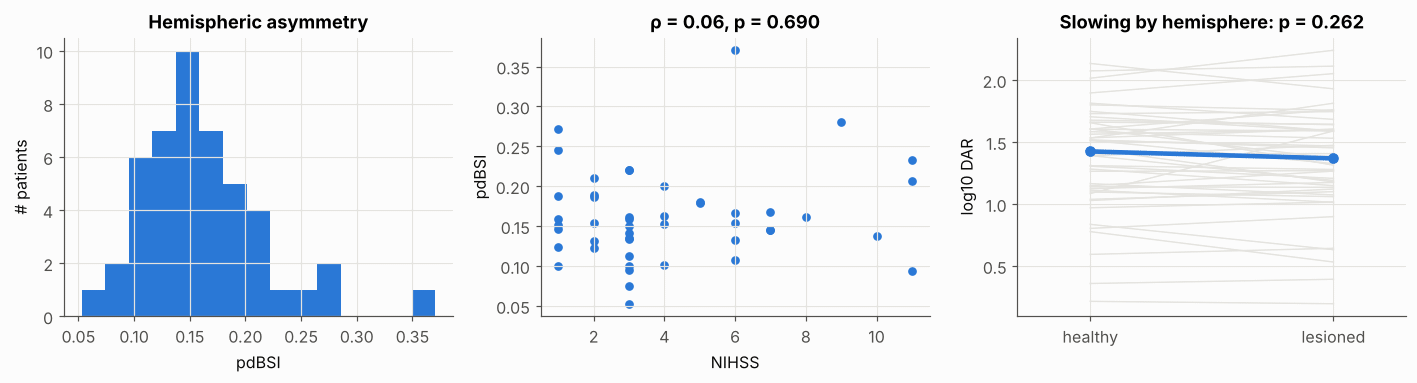

,marker,clinical,rho,p,p_holm
0,pdBSI,NIHSS,0.060,0.690,1.000
1,pdBSI,MBI,-0.100,0.502,1.000
2,pdBSI,mRS,0.246,0.096,0.863
3,pdBSI,Duration,0.289,0.049,0.536
4,DAR healthy side,NIHSS,0.013,0.930,1.000
5,DAR healthy side,MBI,0.007,0.965,1.000
6,DAR healthy side,mRS,0.282,0.054,0.544
7,DAR healthy side,Duration,0.085,0.571,1.000
8,DAR lesioned side,NIHSS,0.115,0.442,1.000
9,DAR lesioned side,MBI,-0.060,0.688,1.000


In [6]:
rows = []
for m_, lab in [("pdbsi", "pdBSI"), ("dar_CL", "DAR healthy side"), ("dar_IL", "DAR lesioned side")]:
    for clin in ["NIHSS", "MBI", "mRS", "Duration"]:
        d = markers[[m_, clin]].dropna(); rho, p = stats.spearmanr(d[m_], d[clin]); rows.append(dict(marker=lab, clinical=clin, rho=rho, p=p))
cor = pd.DataFrame(rows); cor["p_holm"] = holm(cor.p)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(markers.pdbsi, bins=15, color=V.SERIES[0]); ax[0].set_xlabel("pdBSI"); ax[0].set_ylabel("# patients"); ax[0].set_title("Hemispheric asymmetry")
ax[1].scatter(markers.NIHSS, markers.pdbsi, color=V.SERIES[0], s=22); ax[1].set_xlabel("NIHSS"); ax[1].set_ylabel("pdBSI"); r_ = cor[(cor.marker == "pdBSI") & (cor.clinical == "NIHSS")].iloc[0]; ax[1].set_title(f"ρ = {r_.rho:.2f}, p = {r_.p:.3f}")
d = markers[["dar_CL", "dar_IL"]]; ax[2].plot([0, 1], np.log10(d.T.values), color=V.GRID, lw=1); ax[2].plot([0, 1], np.log10(d.median().values), color=V.SERIES[0], lw=3, marker="o")
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(["healthy", "lesioned"]); ax[2].set_xlim(-.3, 1.3); ax[2].set_ylabel("log10 DAR"); ax[2].set_title(f"Slowing by hemisphere: p = {stats.wilcoxon(d.dar_CL, d.dar_IL).pvalue:.3f}")
plt.tight_layout(); plt.show(); cor.round(3)

**Result.** No marker correlates with clinical scores after Holm correction. The strongest trend is lesioned-side DAR vs disability (mRS), ρ = 0.38, uncorrected p = 0.009, Holm p = 0.11, in the expected direction (more slowing, more disability). DAR does not differ between hemispheres (p = 0.26). Two reasons are likely: these are *task* recordings with eye movements, which inflate delta (DAR ≈ 25 here vs ~1–5 at rest), and the lesions are mostly subcortical and mild (median NIHSS 3). A short eyes-closed resting block at the start of each Kandu session would make these markers usable.

## 4 · Functional connectivity: weighted phase-lag index (wPLI)
Connectivity asks whether two regions **oscillate in a coordinated way**. Plain coherence is inflated by **volume conduction**: one source seen by two electrodes looks "connected" with zero lag. **wPLI** (Vinck et al. 2011) uses only the *imaginary* part of the cross-spectrum, i.e. phase relations with a consistent non-zero lag, so instantaneous mixing is discarded.

Below: the change in wPLI (MOVE − REST) between the **healthy-side C electrode** and every other electrode, averaged over patients (mirrored so the healthy hemisphere is on the left), plus the interhemispheric C3–C4 coupling.

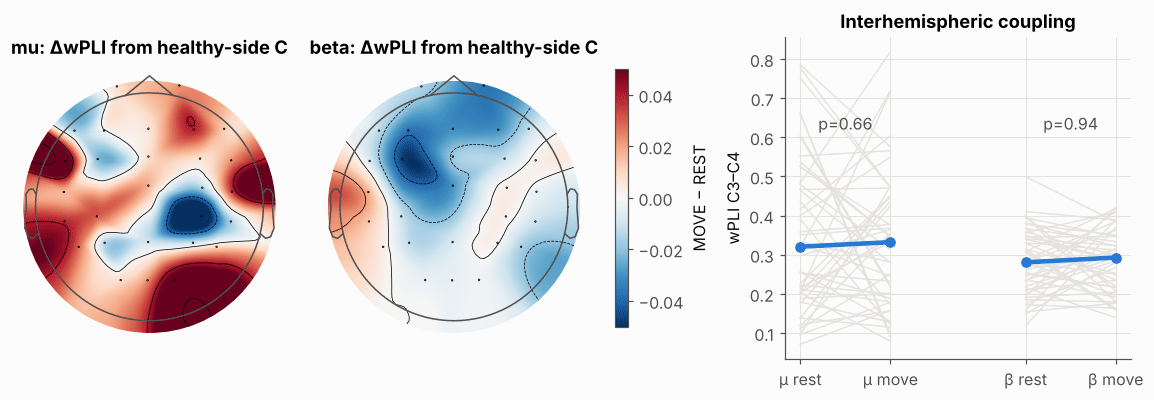

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1.1]))
for a_, band in zip(ax[:2], ["mu", "beta"]):
    w = pd.read_csv(R / f"adv_wpli_{band}_mirrored.csv").drop(columns="subject")
    w = w.drop(columns=[c for c in ["C3"] if c in w])          # seed electrode (CL:C maps to C3 after mirroring)
    mean = w.mean(); p = np.array([stats.wilcoxon(w[c].dropna()).pvalue for c in w]); sig = list(w.columns[holm(p) < 0.05])
    im = V.topomap(mean.to_dict(), a_, vlim=(-0.05, 0.05), title=f"{band}: ΔwPLI from healthy-side C", mask_chs=sig)
plt.colorbar(im, ax=ax[:2], shrink=.8, label="MOVE − REST")
mk = markers
for k, band in enumerate(["mu", "beta"]):
    mv, rs = mk[f"wpli_{band}_interhemi_move"], mk[f"wpli_{band}_interhemi_rest"]
    ax[2].plot([k * 2.5, k * 2.5 + 1], [rs, mv], color=V.GRID, lw=1); ax[2].plot([k * 2.5, k * 2.5 + 1], [rs.median(), mv.median()], color=V.SERIES[0], lw=3, marker="o")
    ax[2].text(k * 2.5 + .5, 0.62, f"p={stats.wilcoxon(mv, rs).pvalue:.2g}", ha="center", color=V.INK2)
ax[2].set_xticks([0, 1, 2.5, 3.5]); ax[2].set_xticklabels(["μ rest", "μ move", "β rest", "β move"]); ax[2].set_ylabel("wPLI C3–C4"); ax[2].set_title("Interhemispheric coupling")
plt.show()

**Result.** No electrode shows a significant change in wPLI from the healthy-side C electrode (Holm-corrected; no electrode marked). The interhemispheric C3–C4 coupling does not change between rest and imagery (μ p = 0.66, β p = 0.94). With ~20 trials of 1.5 s, phase-based connectivity is noisy. For control, local band power remains the stronger and simpler feature. Connectivity is more promising as a *longitudinal* marker of reorganisation across sessions.

## 5 · Group time-frequency maps with cluster-based permutation statistics
Each patient contributes one time × frequency map (Morlet wavelets, dB vs −1.5 to −0.5 s) for affected-hand imagery at the healthy-side and lesioned-side C electrode. Testing ~31 frequencies × ~300 time points one by one would need a massive multiple-comparison correction. The **cluster-based permutation test** (Maris & Oostenveld 2007) instead:

1. computes a t-value per pixel across patients,
2. groups neighbouring supra-threshold pixels into clusters and sums their t-values (cluster mass),
3. builds a null distribution of the largest cluster mass by randomly sign-flipping whole patient maps (1000 permutations),
4. keeps clusters whose mass exceeds 95% of the null.

This controls the family-wise error over the whole map. Black contours mark significant clusters.

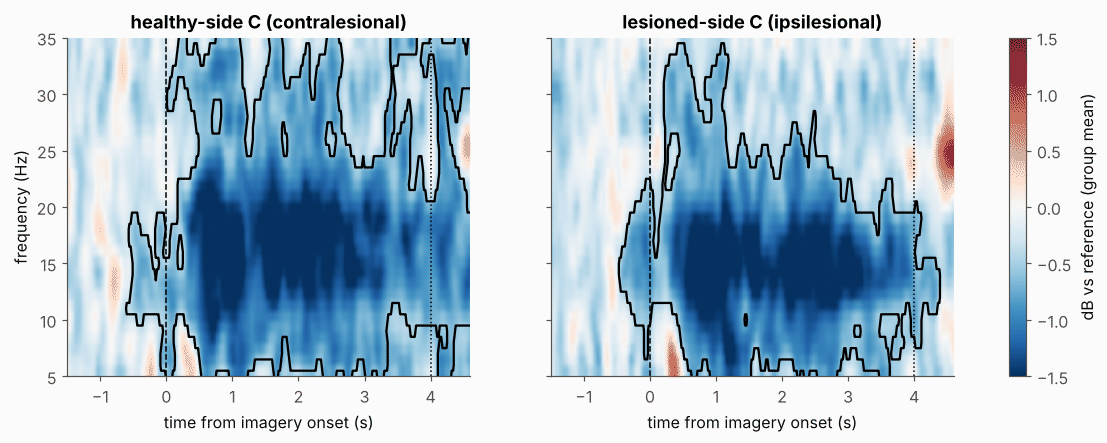

CL: significant pixels = 57.3% of the map; freq range (np.float64(5.0), np.float64(35.0))
IL: significant pixels = 41.6% of the map; freq range (np.float64(5.0), np.float64(34.0))


In [8]:
Z = np.load(R / "adv_tfr_cluster.npz"); t, f = Z["times"], Z["freqs"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a_, tag, ttl in zip(ax, ["CL", "IL"], ["healthy-side C (contralesional)", "lesioned-side C (ipsilesional)"]):
    im = a_.imshow(Z[f"mean_{tag}"], aspect="auto", origin="lower", extent=[t[0], t[-1], f[0], f[-1]], cmap=V.DIVERGING, vmin=-1.5, vmax=1.5)
    if Z[f"sig_{tag}"].any(): a_.contour(t, f, Z[f"sig_{tag}"].astype(float), levels=[.5], colors="k", linewidths=1.5)
    a_.axvline(0, color="k", ls="--", lw=1); a_.axvline(4, color="k", ls=":", lw=1); a_.set_xlabel("time from imagery onset (s)"); a_.set_title(ttl); a_.grid(False)
ax[0].set_ylabel("frequency (Hz)"); plt.colorbar(im, ax=ax, label="dB vs reference (group mean)"); plt.show()
for tag in ["CL", "IL"]:
    sig = Z[f"sig_{tag}"]; print(f"{tag}: significant pixels = {sig.mean()*100:.1f}% of the map;", "freq range", (f[sig.any(1)].min(), f[sig.any(1)].max()) if sig.any() else "none")

**Result.** Across 47 patients, imagery produces a **significant ERD from ~0.3 s to the end of imagery (4 s), centred on 10–25 Hz**, on both hemispheres. The significant cluster covers 57% of the time-frequency map on the healthy side vs 42% on the lesioned side. The healthy-side cluster also extends into high β (25–35 Hz). This is the statistically rigorous version of the Notebook 02 result: it is corrected over every time-frequency point, with no pre-selected window or band.

## 6 · Movement-related cortical potentials (MRCP)
MRCPs are **slow** (0.3–3 Hz) voltage shifts over the motor strip, time-locked to movement. A slowly rising negativity precedes and accompanies the movement (the readiness potential / "Bereitschaftspotential"), and a positive rebound follows. They are a different signal from the μ/β ERD and can be combined with it.

Grand averages (0.3–3 Hz, zero-phase, baseline −2 to −1.5 s): **attempted** movement in SCI (BNCI 2019) and **executed** movement in healthy adults (PhysioNet, n = 49).

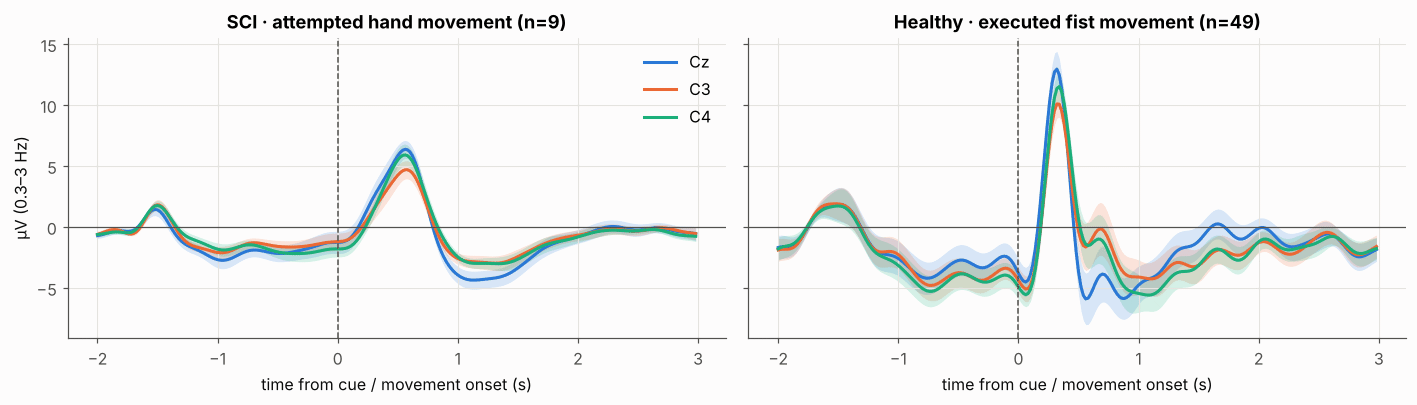

In [9]:
M = np.load(R / "adv_mrcp.npz")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a_, key, ttl in zip(ax, ["bnci2019", "physionet_exec"], ["SCI · attempted hand movement (n=9)", "Healthy · executed fist movement (n=49)"]):
    tt = M[f"{key}_times"]
    for c, col in zip(["Cz", "C3", "C4"], [V.SERIES[0], V.SERIES[1], V.SERIES[2]]):
        d = M[f"{key}_{c}"]; m, se = d.mean(0), d.std(0) / np.sqrt(len(d))
        a_.plot(tt, m, color=col, label=c); a_.fill_between(tt, m - se, m + se, color=col, alpha=.18, lw=0)
    a_.axvline(0, color=V.INK2, ls="--", lw=1); a_.axhline(0, color=V.INK2, lw=.8); a_.set_xlabel("time from cue / movement onset (s)"); a_.set_title(ttl)
ax[0].set_ylabel("µV (0.3–3 Hz)"); ax[0].legend(); plt.tight_layout(); plt.show()

**Result.** The averages are dominated by a **positive peak 0.3–0.6 s after the cue** (larger and earlier with execution), which is the visual or P300-like response to the cue. Before the cue there is a slow **negativity** (−1 to 0 s): the contingent negative variation, i.e. anticipation. A genuine movement-locked readiness potential cannot be separated here, because the time locking is to the *cue*, not to actual movement onset. This supports the Notebook 03 caveat. To use MRCPs in a device, record self-paced attempts, or time-lock to EMG or orthosis onset.

## 7 · How reliable is a patient's ERD?
If a patient's ERD strength changes randomly from one half of the session to the other, it cannot be used to track recovery or to select patients. **Split-half reliability:** split the trials randomly in two halves 200 times, correlate the patients' mean ERD across halves, then apply the Spearman-Brown correction (r_full = 2r / (1 + r)) to estimate the reliability of the full session.

In [10]:
rel = pd.read_csv(R / "adv_reliability.csv"); print(rel.round(3).to_string(index=False))

                      measure  value
split_half_reliability_ERD_CL   0.26


**Result.** The split-half reliability of a patient's healthy-side ERD is **0.26** with ~20 trials. That is too low to rank patients or track recovery from one short session. By the Spearman-Brown formula, reaching 0.8 would need about **11× more trials** (≈ 200 per session), or averaging across several sessions. This is important if ERD strength is to serve as a biomarker of recovery.

## 8 · How many calibration trials are needed?
Within-subject AUC (Riemannian tangent space, all channels) vs the number of **training trials per class**. Each point uses 20 random splits with a held-out 30% test set.

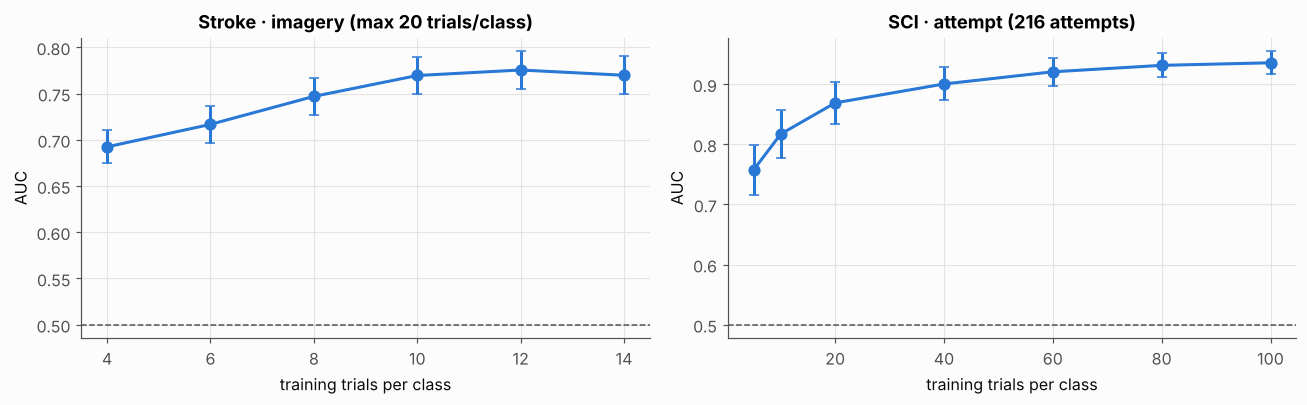

dataset,bnci2019,liu2024
n_per_class,,
4,NaN,0.692
5,0.757,NaN
6,NaN,0.717
8,NaN,0.747
10,0.817,0.770
12,NaN,0.775
14,NaN,0.770
20,0.869,NaN
40,0.900,NaN


In [11]:
lc = pd.read_csv(R / "adv_learning_curve.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_, key, ttl in zip(ax, ["liu2024", "bnci2019"], ["Stroke · imagery (max 20 trials/class)", "SCI · attempt (216 attempts)"]):
    d = lc[lc.dataset == key].groupby("n_per_class").auc; m, se = d.mean(), d.std() / np.sqrt(d.count())
    a_.errorbar(m.index, m, yerr=se, marker="o", ms=7, capsize=3, color=V.SERIES[0]); a_.axhline(.5, color=V.INK2, ls="--", lw=1)
    a_.set_xlabel("training trials per class"); a_.set_ylabel("AUC"); a_.set_title(ttl)
plt.tight_layout(); plt.show()
lc.groupby(["dataset", "n_per_class"]).auc.mean().unstack(0).round(3)

**Result.**
- **Stroke imagery:** AUC rises from 0.69 (4 trials per class) to ~0.77 at 10 trials, then plateaus. More imagery data would help only modestly within one session.
- **SCI attempt:** 0.76 (5 per class) → 0.87 (20) → 0.92 (60) → 0.94 (100).
- **Practical guidance:** with attempted movement, **~40–60 attempts per class** reach > 0.9. That matches IpsiHand's calibration of ~30 move + 30 rest trials.

## 9 · Cross-subject transfer: can a new patient skip calibration?
**Leave-one-subject-out (LOSO):** train on all other subjects, test on the new one, with no labelled data from them. Raw covariance matrices differ a lot between people (head size, impedance, anatomy), so pooled models usually fail. **Riemannian re-centring** (Zanini et al. 2018) whitens each subject's matrices by that subject's own mean, which needs *unlabelled* data only (e.g. the first minutes of a session). All subjects then share the same reference point. We compare:

- **within-subject** (the usual calibrated model),
- **LOSO, raw** (no alignment),
- **LOSO, re-centred** (unsupervised alignment, no labels from the new patient).

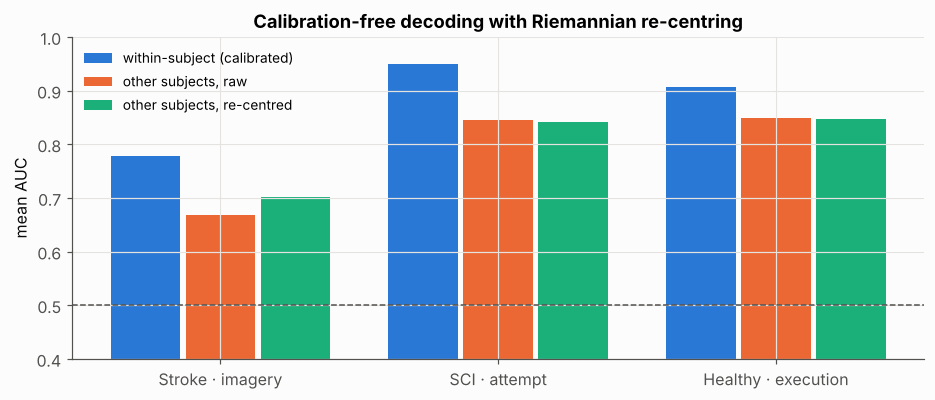

,within,loso_raw,loso_recentred,n,recentred_vs_raw_p,recentred_vs_within_p
dataset,,,,,,
liu2024,0.778,0.669,0.701,47,0.0001,0.0002
bnci2019,0.949,0.846,0.841,9,0.2500,0.0039
physionet_exec,0.906,0.850,0.847,49,0.4540,0.0000


In [12]:
tr = pd.read_csv(R / "adv_transfer.csv")
s = tr.groupby("dataset")[["within", "loso_raw", "loso_recentred"]].mean().reindex(["liu2024", "bnci2019", "physionet_exec"])
fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(s))
for j, (c, lab) in enumerate([("within", "within-subject (calibrated)"), ("loso_raw", "other subjects, raw"), ("loso_recentred", "other subjects, re-centred")]):
    ax.bar(x + (j - 1) * .27, s[c], .25, color=V.SERIES[j], label=lab)
ax.axhline(.5, color=V.INK2, ls="--", lw=1); ax.set_ylim(.4, 1); ax.set_xticks(x); ax.set_xticklabels(["Stroke · imagery", "SCI · attempt", "Healthy · execution"]); ax.set_ylabel("mean AUC"); ax.legend(fontsize=9)
ax.set_title("Calibration-free decoding with Riemannian re-centring"); plt.show()
rows = []
for k, g in tr.groupby("dataset"):
    rows.append(dict(dataset=k, n=len(g), recentred_vs_raw_p=stats.wilcoxon(g.loso_recentred, g.loso_raw).pvalue, recentred_vs_within_p=stats.wilcoxon(g.loso_recentred, g.within).pvalue))
s.round(3).join(pd.DataFrame(rows).set_index("dataset").round(4))

**Result.**
- **Calibration-free performance** (no labelled data from the new person): 0.70 (stroke), 0.84 (SCI attempt), 0.85 (healthy execution). That is 89–93% of the calibrated within-subject AUC (0.78 / 0.95 / 0.91).
- **Re-centring matters for stroke** (0.67 → 0.70, p = 0.0001), where heads, lesions and impedances differ most. It makes no difference in the more homogeneous SCI and healthy groups (p ≥ 0.25).

**For Kandu:** a pooled, re-centred model could run from the first minute of a session. It could then be adapted with the patient's own calibration data, shortening calibration or removing it on good days.

## 10 · Deep learning: EEGNet vs Riemannian geometry
**EEGNet** (Lawhern et al., *J Neural Eng* 2018) is a compact convolutional network designed for EEG (~3,000 parameters here):

1. **temporal convolution** (8 filters, 0.25 s long): learns frequency filters, like a band-pass bank,
2. **depthwise spatial convolution** (2 per filter): learns electrode weightings per frequency, like CSP,
3. **separable convolution**: summarises each feature map over time,
4. average pooling + dropout (0.5) against overfitting, linear output.

Training: Adam optimiser, binary cross-entropy loss, weight decay, each trial z-scored per channel.

Two settings: **stroke, cross-subject** (5 folds over patients, so deep learning sees ~1,500 windows) and **SCI, within-subject** (5-fold CV, ~340 windows per subject).

Stroke, cross-subject:
EEGNet (5-fold over patients)    0.615
Riemann re-centred (LOSO)        0.701
  Wilcoxon p = 0.0014

SCI attempt, within-subject:
model
EEGNet          0.916
TangentSpace    0.946
  Wilcoxon p = 0.0977


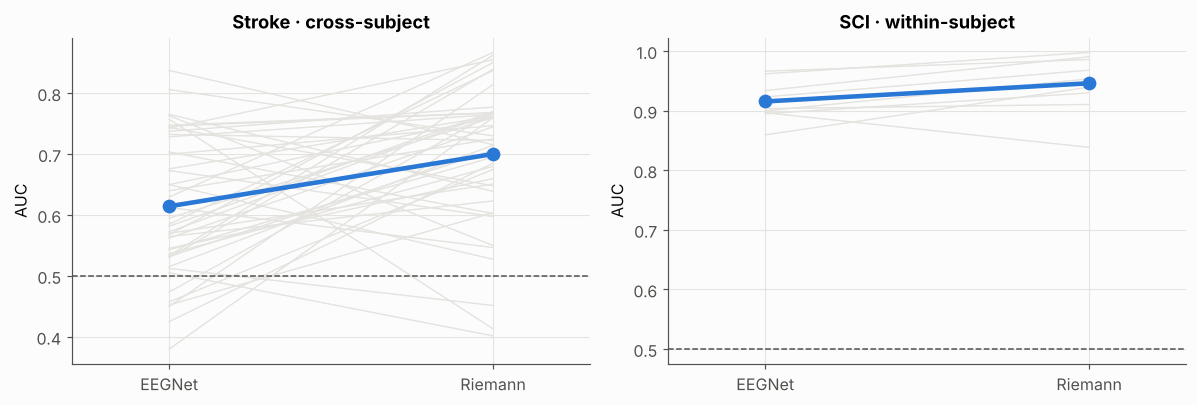

In [13]:
eg = pd.read_csv(R / "adv_eegnet.csv"); tr = pd.read_csv(R / "adv_transfer.csv")
liu = eg[eg.dataset == "liu2024"].set_index("subject").auc.rename("EEGNet (5-fold over patients)")
liu_ts = tr[tr.dataset == "liu2024"].set_index("subject").loso_recentred.rename("Riemann re-centred (LOSO)")
sci = eg[eg.dataset == "bnci2019"].pivot(index="subject", columns="model", values="auc")
print("Stroke, cross-subject:"); print(pd.concat([liu, liu_ts], axis=1).mean().round(3).to_string())
c = pd.concat([liu, liu_ts], axis=1).dropna(); print("  Wilcoxon p =", round(stats.wilcoxon(c.iloc[:, 0], c.iloc[:, 1]).pvalue, 4))
print("\nSCI attempt, within-subject:"); print(sci.mean().round(3).to_string()); print("  Wilcoxon p =", round(stats.wilcoxon(sci.EEGNet, sci.TangentSpace).pvalue, 4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a_, d, ttl in [(ax[0], c, "Stroke · cross-subject"), (ax[1], sci[["EEGNet", "TangentSpace"]], "SCI · within-subject")]:
    a_.plot([0, 1], d.T.values, color=V.GRID, lw=1); a_.plot([0, 1], d.mean().values, color=V.SERIES[0], lw=3, marker="o", ms=8)
    a_.set_xticks([0, 1]); a_.set_xticklabels(["EEGNet", "Riemann"]); a_.set_xlim(-.3, 1.3); a_.axhline(.5, color=V.INK2, ls="--", lw=1); a_.set_ylabel("AUC"); a_.set_title(ttl)
plt.tight_layout(); plt.show()

**Result.**
- **Stroke, cross-subject:** EEGNet reaches 0.62 vs 0.70 for the re-centred Riemannian model (p = 0.001).
- **SCI attempt, within-subject:** 0.92 vs 0.95 (n.s., p = 0.10).

With hundreds to a few thousand training windows, a ~3k-parameter network does not beat Riemannian geometry. That is consistent with recent benchmarks (MOABB) at this data scale. Deep learning becomes attractive with **Kandu's own data scale**: many patients × many sessions, where pre-training on the pooled data and fine-tuning per patient can pay off.

## 11 · Summary
1. **Artefacts:** EOG regression is an adequate real-time substitute for ICA at the motor electrodes.
2. **Resting-spectrum and symmetry markers** do not separate hemispheres or track clinical scores in *task* data. Add a short resting block if these markers are wanted.
3. **The task-related healthy-side ERD is robust at group level** (cluster-corrected), but **unreliable within one short session** (r = 0.26). As a recovery biomarker it needs more trials or several sessions.
4. **Calibration:** ~40–60 attempts per class for > 0.9 with attempted movement. A **re-centred cross-subject model** gets 89–93% of that with no calibration.
5. **Model choice at this data scale:** Riemannian tangent space ≥ EEGNet. Revisit deep learning with multi-session, multi-patient data.